# Roadkill · Comparación de clasificación: frontend, MLP y LSTM

**Una sola tarea:** predecir si una celda BNG de 10 km registra al menos una
colisión DVC en el mes objetivo. **Métricas:** ROC-AUC, AP, Brier y F1.

Este cuaderno contiene exclusivamente la carga y preparación de datos,
entrenamiento, calibración/umbrales y evaluación de estas tres familias.

| Modelo | Procedencia y prueba |
|---|---|
| Principal del frontend | RF con los hiperparámetros seleccionados en Reto 5, Platt temporal y ajuste de odds por mes; además se auditan las predicciones exactas del ZIP |
| Nueva MLP | Misma arquitectura y preprocesamiento de la clasificación binaria del capítulo 8 ejecutado: Dense 64/32, Dropout 0,15, L2 1e-5, sigmoid |
| LSTM de presencia | Predicciones originales del Reto 9 verificadas desde el ZIP; entrenamiento explícito de una reconstrucción sobre secuencias de 12 meses |

**Distinción de procedencia:** el ZIP no contiene el código ni los pesos originales
de la LSTM. Su evaluación archivada es exacta; la arquitectura reentrenable que se
define aquí es una reconstrucción declarada, no una reproducción exacta del Reto 9.
Las tablas identifican cada procedencia. La MLP se inicializa de nuevo, por lo que
sus métricas no tienen por qué coincidir exactamente con la ejecución anterior.

## 1 · Cómo ejecutar

1. Guarda este Jupyter en `<proyecto>/notebooks/`.
2. Deja el ZIP V11 proporcionado junto al cuaderno o en la raíz del proyecto;
   también sirve la carpeta de la aplicación descomprimida con su directorio `data`.
3. Usa **Reiniciar kernel y ejecutar todas las celdas**.
4. Si hace falta, configura `PROJECT_ROOT_OVERRIDE` en el cargador y
   `FRONTEND_SOURCE_OVERRIDE` con la ruta de tu ZIP o aplicación.

Dependencias: `numpy pandas matplotlib scikit-learn tensorflow nbformat joblib`.
Si falta alguna, ejecuta `%pip install numpy pandas matplotlib scikit-learn tensorflow nbformat joblib`
en una celda aparte y reinicia el kernel. No se instala nada automáticamente.

`QUICK_RUN=True` sirve exclusivamente para comprobar el funcionamiento con pocas
épocas y árboles. La ejecución normal queda en `False`.

In [7]:
from pathlib import Path
import os, io, json, zipfile, hashlib, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nbformat, joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
    f1_score, precision_score, recall_score, accuracy_score, confusion_matrix,
    roc_curve, precision_recall_curve, classification_report)
try:
    import tensorflow as tf
except ImportError as exc:
    raise ImportError('Instala TensorFlow en el kernel de este Jupyter y reinícialo.') from exc

SEED=42
QUICK_RUN=False
FRONTEND_SOURCE_OVERRIDE=None
SUBTRAIN_END_YEAR, VALIDATION_YEAR, TEST_YEAR = 2015, 2016, 2017
CELL_M, ECOLS = 10000, 80
WINDOW=12
KEYS=['cell','year','month']
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
try:
    tf.config.threading.set_intra_op_parallelism_threads(2)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    print('El kernel ya inicializó TensorFlow; mantiene sus hilos actuales.')
print('Python:',platform.python_version(),'| TensorFlow:',tf.__version__,'| breve:',QUICK_RUN)

def dataset_tf(X,y=None,training=False,batch=64):
    ds=tf.data.Dataset.from_tensor_slices(X if y is None else (X,y))
    ds=ds.cache()
    if training:ds=ds.shuffle(len(X),seed=SEED,reshuffle_each_iteration=True)
    opts=tf.data.Options();opts.threading.private_threadpool_size=2
    return ds.batch(batch).with_options(opts).prefetch(1)
def epochs(n):return min(n,3) if QUICK_RUN else n

Python: 3.10.6 | TensorFlow: 2.21.0 | breve: False


## 2 · Acceso oficial del proyecto

Se conservan `cargar_dataset()` y `cargar_archivo()`, con el patrón
**local → servidor → caché**, extraídas de MVP-B si está disponible.
El cargador alternativo es el de Reto 5: usa `scripts/pipeline/config.py` o
`IA_DATA_SERVER_URL` / `IA_DATA_API_TOKEN`. No se introduce otra fuente de datos.

In [8]:
# ===============================================================
# CARGADOR COMPATIBLE CON MVP-B · LOCAL -> REMOTO -> CACHÉ
# ===============================================================
# Opcional: si Jupyter se abre fuera de la carpeta del proyecto,
# configura aquí su ruta real, por ejemplo r"C:\Users\Usuario\p_IA".
PROJECT_ROOT_OVERRIDE = None
# Opcional: normalmente NO es necesario porque scripts/pipeline/config.py
# o las variables de entorno ya contienen la dirección. No guardes tokens aquí.
DATA_SERVER_URL_OVERRIDE = None

import os
import io
import sys
import urllib.request
import importlib
from pathlib import Path

try:
    import requests
except ImportError:
    requests = None


def _encontrar_mvp(base: Path):
    """Busca únicamente en las ubicaciones usadas por los demás retos."""
    opciones = [
        base / "notebooks" / "MVP_B_dos_niveles.ipynb",
        base / "notebooks" / "MVP_B_dos_niveles(1).ipynb",
        base / "MVP_B_dos_niveles.ipynb",
        base / "MVP_B_dos_niveles(1).ipynb",
    ]
    opciones.extend(sorted((base / "notebooks").glob("MVP_B_dos_niveles*.ipynb"))
                    if (base / "notebooks").is_dir() else [])
    for path in opciones:
        if path.is_file():
            return path.resolve()
    return None


def _detectar_raiz_proyecto(cwd: Path):
    if PROJECT_ROOT_OVERRIDE:
        raiz = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
        if not raiz.is_dir():
            raise FileNotFoundError(f"PROJECT_ROOT_OVERRIDE no es una carpeta: {raiz}")
        return raiz

    # No buscar de manera recursiva dentro de los grandes datasets.
    cwd = cwd.resolve()
    bases = [cwd, *list(cwd.parents)[:4]]
    candidates = []
    for base in bases:
        if base.name.lower() == "notebooks":
            candidates.append(base.parent)
        candidates.append(base)
    # Duplicados sin reordenar.
    candidates = list(dict.fromkeys(candidates))
    def score(base):
        return (
            int((base / "scripts" / "pipeline" / "config.py").is_file()) * 16
            + int((base / "Datos" / "trafico" / "aadf_data").is_dir()) * 8
            + int((base / "Datos" / "dvc").is_dir()) * 4
            + int(_encontrar_mvp(base) is not None) * 2
            + int((base / "notebooks").is_dir())
        )
    ranked = [(score(x), i, x) for i, x in enumerate(candidates)]
    best_score, _, best = max(ranked, key=lambda t: (t[0], -t[1]))
    if best_score:
        return best
    return cwd.parent if cwd.name.lower() == "notebooks" else cwd

CWD = Path.cwd()
RAIZ = _detectar_raiz_proyecto(CWD)
RAIZ_PROYECTO = RAIZ
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

SOURCE_NOTEBOOK = _encontrar_mvp(RAIZ)
LOADER_ORIGEN = None
# Las versiones antiguas de MVP-B incluían una sola celda con ambas
# definiciones. NO usamos next(...) sin valor por defecto: en otras
# versiones las funciones podrían estar separadas entre varias celdas.
if SOURCE_NOTEBOOK is not None:
    try:
        import nbformat
        _nb_src = nbformat.read(SOURCE_NOTEBOOK, as_version=4)
        _loader_cell = next((
            c.source for c in _nb_src.cells
            if c.cell_type == "code"
            and "def cargar_dataset" in c.source
            and "def cargar_archivo" in c.source
        ), None)
        if _loader_cell is not None:
            _loader_source = "\n".join(
                line for line in _loader_cell.splitlines()
                if not line.lstrip().startswith("%")
            )
            _cut_markers = ["\nROOT = str(RAIZ)", "\n_cost = cargar_dataset("]
            _positions = [
                pos for marker in _cut_markers
                if (pos := _loader_source.find(marker)) != -1
            ]
            if _positions:
                _loader_source = _loader_source[:min(_positions)]
            # Aislamiento: un fallo en MVP-B no altera el espacio del Reto 5.
            _loader_ns = dict(globals())
            exec(compile(_loader_source, str(SOURCE_NOTEBOOK), "exec"), _loader_ns)
            if not (callable(_loader_ns.get("cargar_dataset"))
                    and callable(_loader_ns.get("cargar_archivo"))):
                raise RuntimeError("El bloque de MVP-B no define ambas funciones.")
            # Las funciones originales seguirán compartiendo este namespace.
            _loader_ns["RAIZ"] = RAIZ
            _loader_ns["RAIZ_PROYECTO"] = RAIZ
            cargar_dataset = _loader_ns["cargar_dataset"]
            cargar_archivo = _loader_ns["cargar_archivo"]
            LOADER_ORIGEN = "Funciones originales de MVP_B_dos_niveles.ipynb"
        else:
            print("[Aviso] MVP-B encontrado, pero ambas funciones no están "
                  "en una misma celda. Se usará el cargador alternativo.")
    except Exception as exc:
        print("[Aviso] No se pudo reutilizar el cargador de MVP-B:",
              type(exc).__name__, str(exc)[:180])

if LOADER_ORIGEN is None:
    # Repetir el contrato local/remoto/caché que implementan los otros retos.
    # Importar la configuración desde la raíz DETECTADA, evitando reutilizar
    # por error módulos de otro proyecto abiertos antes en el kernel.
    try:
        config_file = RAIZ / "scripts" / "pipeline" / "config.py"
        if not config_file.is_file():
            raise ModuleNotFoundError(f"No existe {config_file}")
        # Preferimos importar normalmente como en los otros notebooks.
        _config_mod = importlib.import_module("scripts.pipeline.config")
        if Path(_config_mod.__file__).resolve() != config_file.resolve():
            raise ImportError("El config.py importado corresponde a otra raíz.")
        SERVER_URL = str(getattr(_config_mod, "SERVER_URL", "") or "").rstrip("/")
        API_TOKEN = str(getattr(_config_mod, "API_TOKEN", "") or "")
    except (ImportError, ModuleNotFoundError, AttributeError, ValueError):
        SERVER_URL = os.getenv("IA_DATA_SERVER_URL", "").rstrip("/")
        API_TOKEN = os.getenv("IA_DATA_API_TOKEN", "")

    if DATA_SERVER_URL_OVERRIDE:
        SERVER_URL = str(DATA_SERVER_URL_OVERRIDE).strip().rstrip("/")

    def _candidatos_dataset(nombre_dataset: str) -> list[str]:
        alias = {
            "dft_aadf": ["aadf", "trafico/aadf_data/dft_traffic_counts_aadf.csv",
                         "dft_traffic_counts_aadf.csv"],
            "deer_claims": ["deer_claims_uk_2021_2025",
                            "deer_claims_uk_2021_2025.csv",
                            "Datos/deer_claims_uk_2021_2025.csv"],
            "dvc_scotland": ["dvc_geojson", "dvc_scotland_zip",
                             "dvc/DVC_SCOTLAND_GEOJSON_4326.zip",
                             "dvc/DVC_SCOTLAND.geojson"],
            "dvc_geojson": ["dvc_scotland", "dvc_scotland_zip",
                            "dvc/DVC_SCOTLAND.geojson",
                            "dvc/DVC_SCOTLAND_GEOJSON_4326/DVC_SCOTLAND.geojson"],
            "corine_features": ["entorno/corine_features.csv",
                                "corine_features.csv"],
        }
        return list(dict.fromkeys([nombre_dataset, *alias.get(nombre_dataset, [])]))

    def _descargar_de_servidor(nombre_dataset: str) -> bytes:
        if not SERVER_URL:
            raise FileNotFoundError(
                f"No se encontró el archivo local para '{nombre_dataset}' "
                f"y no está configurada la URL del servidor.\n"
                f"Raíz detectada: {RAIZ}\n"
                f"Config esperado: {RAIZ / 'scripts/pipeline/config.py'}\n"
                "Coloca este Jupyter en <proyecto>/notebooks, o define "
                "PROJECT_ROOT_OVERRIDE con tu ruta real, o configura "
                "IA_DATA_SERVER_URL e IA_DATA_API_TOKEN (sin pegar el token en el notebook)."
            )
        headers = {"Authorization": f"Bearer {API_TOKEN}"} if API_TOKEN else {}
        last_err = None
        for candidate in _candidatos_dataset(nombre_dataset):
            url = f"{SERVER_URL}/datasets/{candidate}"
            if requests is not None:
                try:
                    r = requests.get(url, headers=headers, timeout=180)
                    if r.status_code == 200:
                        return r.content
                    last_err = f"HTTP {r.status_code}"
                except Exception as exc:
                    last_err = f"{type(exc).__name__}: {exc}"
            else:
                try:
                    req = urllib.request.Request(url, headers=headers)
                    with urllib.request.urlopen(req, timeout=180) as response:
                        return response.read()
                except Exception as exc:
                    last_err = f"{type(exc).__name__}: {exc}"
        raise ConnectionError(
            f"No se pudo descargar '{nombre_dataset}' desde el servidor "
            f"configurado. Último error: {last_err}"
        )

    def _resolver_ruta(ruta_local: Path | str):
        path = Path(ruta_local)
        return path if path.is_absolute() else RAIZ / path

    def cargar_dataset(nombre_dataset: str,
                       ruta_local: Path | str | None = None, **kwargs) -> pd.DataFrame:
        ruta = _resolver_ruta(ruta_local or f"Datos/{nombre_dataset}.csv")
        if ruta.is_file():
            print(f"[Local] Leyendo {nombre_dataset}: {ruta}")
            return (pd.read_parquet(ruta, **kwargs) if ruta.suffix.lower()
                    in {".parquet", ".pq"} else pd.read_csv(ruta, **kwargs))
        print(f"[Remoto] No existe localmente: {ruta}")
        content = _descargar_de_servidor(nombre_dataset)
        try:
            ruta.parent.mkdir(parents=True, exist_ok=True)
            ruta.write_bytes(content)
            print(f"[Caché] {ruta}")
        except OSError as exc:
            print(f"[Aviso] Sin caché local: {type(exc).__name__}: {exc}")
        return (pd.read_parquet(io.BytesIO(content), **kwargs) if
                ruta.suffix.lower() in {".parquet", ".pq"}
                else pd.read_csv(io.BytesIO(content), **kwargs))

    def cargar_archivo(nombre_dataset: str, ruta_local: Path | str) -> Path:
        ruta = _resolver_ruta(ruta_local)
        if ruta.is_file():
            print(f"[Local] {ruta}")
            return ruta
        print(f"[Remoto] No existe localmente: {ruta}")
        content = _descargar_de_servidor(nombre_dataset)
        ruta.parent.mkdir(parents=True, exist_ok=True)
        ruta.write_bytes(content)
        print(f"[Caché] {ruta}")
        return ruta
    LOADER_ORIGEN = "Cargador compatible local/remoto/caché (alternativo)"

assert callable(cargar_dataset) and callable(cargar_archivo)
print("Raíz detectada:", RAIZ)
print("Origen del cargador:", LOADER_ORIGEN)
print("MVP-B localizado:", SOURCE_NOTEBOOK if SOURCE_NOTEBOOK else "No")
print("AADF local:", (RAIZ / "Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv").is_file())
print("Config oficial:", (RAIZ / "scripts/pipeline/config.py").is_file())
print("Si falla la carga, comprueba el diagnóstico anterior antes de continuar.")

Raíz detectada: C:\Users\Gabriel\Documents\GitHub\IA
Origen del cargador: Cargador compatible local/remoto/caché (alternativo)
MVP-B localizado: No
AADF local: True
Config oficial: True
Si falla la carga, comprueba el diagnóstico anterior antes de continuar.


## 3 · AADF y DVC Scotland

Únicos datasets brutos: DfT AADF y DVC Scotland. Las predicciones del ZIP se usan
después como resultados de referencia, nunca como variables de entrenamiento.
Los registros sin coordenadas BNG o fecha válida se contabilizan y se excluyen.

In [9]:
AADF_CSV = RAIZ / 'Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv'
DVC_ZIP = RAIZ / 'Datos/dvc/DVC_SCOTLAND_GEOJSON_4326.zip'
DVC_GEOJSON = RAIZ / 'Datos/dvc/DVC_SCOTLAND.geojson'
DVC_FOLDER = RAIZ / 'Datos/dvc/DVC_SCOTLAND_GEOJSON_4326/DVC_SCOTLAND.geojson'
AADF_USECOLS = ['count_point_id','year','region_name','local_authority_name',
               'road_name','road_category','easting','northing','link_length_km','all_motor_vehicles']
aadf = cargar_dataset('dft_aadf', AADF_CSV, usecols=AADF_USECOLS)

def leer_geojson(path):
    path = Path(path)
    if zipfile.is_zipfile(path):
        with zipfile.ZipFile(path) as archive:
            candidates = sorted(archive.namelist(), key=lambda s: (not s.lower().endswith('.geojson'), s))
            for name in candidates:
                if name.lower().endswith(('.geojson','.json')):
                    data = json.loads(archive.read(name).decode('utf-8-sig'))
                    if isinstance(data,dict) and isinstance(data.get('features'),list): return data
        raise ValueError('El ZIP no contiene un GeoJSON con features.')
    data = json.loads(path.read_bytes().decode('utf-8-sig'))
    if not isinstance(data,dict) or not isinstance(data.get('features'),list):
        raise ValueError('DVC no contiene una FeatureCollection válida.')
    return data

gj, dvc_file, errores_dvc = None, None, []
# Primero archivos locales reconocidos; después el mismo servidor del proyecto.
for path in [DVC_GEOJSON, DVC_FOLDER, DVC_ZIP]:
    if path.is_file():
        try: gj=leer_geojson(path); dvc_file=path; break
        except (ValueError, OSError, zipfile.BadZipFile) as exc:
            errores_dvc.append((path.name, type(exc).__name__))
if gj is None:
    for name,path in [('dvc_scotland',DVC_ZIP),('dvc_geojson',DVC_GEOJSON),('dvc_geojson',DVC_FOLDER)]:
        try:
            dvc_file=cargar_archivo(name,path); gj=leer_geojson(dvc_file); break
        except Exception as exc: errores_dvc.append((name,type(exc).__name__))
if gj is None:
    raise FileNotFoundError(f'No se pudo cargar DVC mediante el cargador del proyecto: {errores_dvc}')

rows=[]
for feat in gj['features']:
    p=feat.get('properties') or {}
    rows.append({
        'easting':p.get('OS_EASTING'), 'northing':p.get('OS_NORTHIN'),
        'year':p.get('YEAR'), 'month':p.get('MONTH')
    })
dvc=pd.DataFrame(rows,columns=['easting','northing','year','month'])
for c in ['easting','northing','year','month']: dvc[c]=pd.to_numeric(dvc[c],errors='coerce')
for c in ['year','easting','northing','link_length_km','all_motor_vehicles']:
    aadf[c]=pd.to_numeric(aadf[c],errors='coerce')
for name,frame in [('AADF',aadf),('DVC',dvc)]:
    print(name,frame.shape,'| duplicados exactos:',frame.duplicated().sum())
    display(pd.DataFrame({'tipo':frame.dtypes.astype(str),'nulos':frame.isna().sum()}))
    display(frame.head(3))
DATA_SOURCE={'AADF':str(AADF_CSV),'DVC':str(dvc_file),'cargador':LOADER_ORIGEN}

[Local] Leyendo dft_aadf: C:\Users\Gabriel\Documents\GitHub\IA\Datos\trafico\aadf_data\dft_traffic_counts_aadf.csv
AADF (600551, 10) | duplicados exactos: 0


,tipo,nulos
count_point_id,int64,0
year,int64,0
region_name,object,0
local_authority_name,object,0
road_name,object,0
road_category,object,0
easting,int64,0
northing,int64,0
link_length_km,float64,134684
all_motor_vehicles,int64,0


,count_point_id,year,region_name,local_authority_name,road_name,road_category,easting,northing,link_length_km,all_motor_vehicles
0,51,2000,South West,Isles of Scilly,A3111,PA,90200,10585,0.3,1430
1,51,2001,South West,Isles of Scilly,A3111,PA,90200,10585,0.3,1446
2,51,2002,South West,Isles of Scilly,A3111,PA,90200,10585,0.3,1518


DVC (16383, 4) | duplicados exactos: 378


,tipo,nulos
easting,float64,0
northing,float64,0
year,int64,0
month,int64,0


,easting,northing,year,month
0,221650.0,673392.0,2009,5
1,253446.0,674429.0,2009,5
2,309246.0,725828.0,2009,5


## 4 · Dos preparaciones originales, un mismo objetivo

**RF:** se reproduce la agregación del Reto 5 (`cell × year`, expandida a los
12 meses). Usa las variables AADF del año objetivo, como el frontend original.
Por tanto esta comparación es retrospectiva: no demuestra que el AADF anual
estuviese disponible al principio de cada mes.

**MLP:** se conserva la preparación del capítulo 8: ámbito fijado con AADF 2008,
tráfico/red del año anterior y calendario. No se cambia su prueba para hacerla ganar.

**LSTM reconstruida:** toma 12 meses anteriores de ese panel, con tráfico previo,
calendario, presencia histórica y log-conteo histórico. El mes objetivo nunca
aparece en la secuencia. Predicción móvil a un mes: los meses ya observados de
2017 pueden formar parte del pasado para un objetivo posterior de 2017.

Los cero DVC significan «sin registros en esta fuente», no ausencia demostrada
de colisiones. Se mantiene la hipótesis de cobertura mensual. **2018 queda fuera.**

In [10]:
def valid_bng(frame):
    return (np.isfinite(frame['easting']) & np.isfinite(frame['northing'])
            & frame['easting'].between(0,799999) & frame['northing'].between(0,1299999))
def cell_10km(easting,northing):
    # Misma numeración que Reto 5/6. Se validan rangos antes, sin recortar valores erróneos.
    return (np.floor(np.asarray(northing)/CELL_M).astype(int)*ECOLS
            + np.floor(np.asarray(easting)/CELL_M).astype(int))
def mode_or_unknown(s):
    s=s.dropna().astype(str).str.strip()
    return s.mode().iloc[0] if len(s) else 'desconocido'

audit_input={'aadf_rows':len(aadf),'dvc_rows':len(dvc),
             'aadf_invalid_bng':int((~valid_bng(aadf)).sum()),
             'dvc_invalid_bng':int((~valid_bng(dvc)).sum())}
aadf_scot=aadf.loc[aadf['region_name'].astype(str).str.strip().eq('Scotland')
    & valid_bng(aadf) & aadf['year'].between(2008,2017)].copy()
dvc_valid=dvc.loc[valid_bng(dvc) & dvc['year'].between(2008,2017)
    & dvc['month'].between(1,12) & dvc['year'].mod(1).eq(0)
    & dvc['month'].mod(1).eq(0)].copy()
if aadf_scot.empty or dvc_valid.empty: raise ValueError('AADF Scotland o DVC quedó vacío tras validar.')
aadf_scot['year']=aadf_scot['year'].astype(int)
dvc_valid[['year','month']]=dvc_valid[['year','month']].astype(int)
aadf_scot['cell']=cell_10km(aadf_scot['easting'],aadf_scot['northing'])
dvc_valid['cell']=cell_10km(dvc_valid['easting'],dvc_valid['northing'])
missing_years=set(range(2008,2018))-set(dvc_valid['year'])
if missing_years: raise ValueError(f'DVC no tiene registros en estos años: {sorted(missing_years)}. Revisa cobertura.')
for c in ['all_motor_vehicles','link_length_km']:
    aadf_scot.loc[aadf_scot[c]<0,c]=np.nan
study_cells=np.sort(aadf_scot.loc[aadf_scot['year'].eq(2008),'cell'].unique())
if not len(study_cells): raise ValueError('Falta AADF Scotland de 2008 para fijar el ámbito espacial.')
annual=(aadf_scot.groupby(['cell','year'],as_index=False).agg(
    traffic_mean=('all_motor_vehicles','mean'), traffic_sum=('all_motor_vehicles','sum'),
    link_length_km=('link_length_km',lambda s:s.sum(min_count=1)),
    count_points=('count_point_id','nunique'), easting_mean=('easting','mean'),
    northing_mean=('northing','mean'), road_category=('road_category',mode_or_unknown),
    local_authority_name=('local_authority_name',mode_or_unknown), road_name=('road_name',mode_or_unknown)))
annual['source_year']=annual['year']
annual['year']=annual['year']+1
keys=pd.MultiIndex.from_product([study_cells,range(2009,2018),range(1,13)],
                               names=['cell','year','month']).to_frame(index=False)
df=keys.merge(annual,on=['cell','year'],how='left',validate='many_to_one')
counts=(dvc_valid.groupby(['cell','year','month']).size().rename('dvc_count').reset_index())
df=df.merge(counts,on=['cell','year','month'],how='left',validate='one_to_one')
df['dvc_count']=df['dvc_count'].fillna(0).astype(int)
df['target_presence']=df['dvc_count'].gt(0).astype(int)
df['Date']=pd.to_datetime(dict(year=df['year'],month=df['month'],day=1))
df['days_in_month']=df['Date'].dt.days_in_month
df['month_sin']=np.sin(2*np.pi*df['month']/12)
df['month_cos']=np.cos(2*np.pi*df['month']/12)
df['exposure_vkm_proxy']=df['traffic_mean']*df['link_length_km']*df['days_in_month']
log_raw=['traffic_mean','traffic_sum','link_length_km','count_points','exposure_vkm_proxy']
log_cols=['log_'+c for c in log_raw]
for c in log_raw: df['log_'+c]=np.log1p(df[c])
cat_cols=['road_category','local_authority_name']
for c in cat_cols+['road_name']: df[c]=df[c].fillna('desconocido').astype(str)
df=df.sort_values(['Date','cell']).reset_index(drop=True)
df_raw=df.copy()
audit_input.update({'study_cells_2008':len(study_cells),
    'dvc_2018_excluded':int(dvc['year'].eq(2018).sum()),
    'dvc_outside_study_cells':int((~dvc_valid['cell'].isin(study_cells)).sum()),
    'rows_missing_previous_aadf':int(df['source_year'].isna().sum())})
assert df['year'].max()==2017 and not df.duplicated(['cell','year','month']).any()
assert (df.loc[df['source_year'].notna(),'source_year'] < df.loc[df['source_year'].notna(),'year']).all()
display(pd.Series(audit_input,name='auditoría'))
display(df.head())

aadf_rows                     600551
dvc_rows                       16383
aadf_invalid_bng                   0
dvc_invalid_bng                    0
study_cells_2008                 528
dvc_2018_excluded                872
dvc_outside_study_cells         1156
rows_missing_previous_aadf         0
Name: auditoría, dtype: int64

,cell,year,month,traffic_mean,traffic_sum,link_length_km,count_points,easting_mean,northing_mean,road_category,...,Date,days_in_month,month_sin,month_cos,exposure_vkm_proxy,log_traffic_mean,log_traffic_sum,log_link_length_km,log_count_points,log_exposure_vkm_proxy
0,4264,2009,1,484.000,484.0,2.5,1,243000.00,539000.000,PA,...,2009-01-01,31,0.5,0.866025,3.751000e+04,6.184149,6.184149,1.252763,0.693147,10.532390
1,4341,2009,1,1129.000,2258.0,16.6,2,211735.00,543600.000,PA,...,2009-01-01,31,0.5,0.866025,5.809834e+05,7.029973,7.722678,2.867899,1.098612,13.272479
2,4343,2009,1,799.500,1599.0,21.6,2,233400.00,543650.000,PA,...,2009-01-01,31,0.5,0.866025,5.353452e+05,6.685237,7.377759,3.117950,1.098612,13.190669
3,4344,2009,1,1247.000,2494.0,8.3,2,243510.50,545000.000,PA,...,2009-01-01,31,0.5,0.866025,3.208531e+05,7.129298,7.822044,2.230014,1.098612,12.678742
4,4420,2009,1,3254.125,26033.0,19.1,8,205991.25,556509.375,PA,...,2009-01-01,31,0.5,0.866025,1.926767e+06,8.087986,10.167159,3.000720,2.197225,14.471355


In [11]:
def original_cell_10km(easting,northing):
    col=np.clip(np.floor(np.asarray(easting,dtype=float)/CELL_M).astype(int),0,ECOLS-1)
    row=np.clip(np.floor(np.asarray(northing,dtype=float)/CELL_M).astype(int),0,129)
    return row*ECOLS+col

# Panel del Reto 5: conserva el año actual y todas las celdas AADF presentes ese año.
aadf_rf=aadf.loc[aadf['region_name'].eq('Scotland') & aadf['year'].between(2008,2017)
                 & valid_bng(aadf)].copy()
aadf_rf['year']=aadf_rf['year'].astype(int)
aadf_rf['cell']=original_cell_10km(aadf_rf['easting'],aadf_rf['northing'])
def mode_or_nan(s):
    v=s.dropna();return v.mode().iloc[0] if len(v) else np.nan
rf_annual=(aadf_rf.groupby(['cell','year'],as_index=False).agg(
    traffic_mean=('all_motor_vehicles','mean'),traffic_sum=('all_motor_vehicles','sum'),
    link_length_km=('link_length_km','sum'),count_points=('count_point_id','nunique'),
    easting_mean=('easting','mean'),northing_mean=('northing','mean'),
    road_category=('road_category',mode_or_nan),local_authority_name=('local_authority_name',mode_or_nan)))
rf_panel=rf_annual.merge(pd.DataFrame({'month':range(1,13)}),how='cross')
rf_panel=rf_panel.merge(counts,on=KEYS,how='left',validate='one_to_one')
rf_panel['dvc_count']=rf_panel['dvc_count'].fillna(0).astype(int)
rf_panel['target_presence']=rf_panel['dvc_count'].gt(0).astype(int)
rf_panel=rf_panel.sort_values(KEYS).reset_index(drop=True)
BASE_NUMERIC=['year','traffic_mean','traffic_sum','link_length_km','count_points','easting_mean','northing_mean']
BASE_CATEGORICAL=['road_category','local_authority_name']
BASE_FEATURES=BASE_NUMERIC+BASE_CATEGORICAL
num_mlp=log_cols+['year','month_sin','month_cos','easting_mean','northing_mean']
cat_mlp=['road_category','local_authority_name']
MLP_FEATURES=num_mlp+cat_mlp

def split_indices(frame):
    masks=[frame['year']<=2015,frame['year']==2016,frame['year']==2017]
    parts=[np.flatnonzero(mask) for mask in masks]
    for name,ix in zip(['train','validation','test'],parts):
        if not len(ix) or frame.iloc[ix]['target_presence'].nunique()!=2:
            raise ValueError(f'{name} necesita filas y las dos clases binarias.')
    return parts
rf_tr,rf_va,rf_te=split_indices(rf_panel)
mlp_tr,mlp_va,mlp_te=split_indices(df)
partition_rows=[]
for name,frame,parts in [('RF',rf_panel,[rf_tr,rf_va,rf_te]),('MLP / LSTM',df,[mlp_tr,mlp_va,mlp_te])]:
    for split,ix in zip(['train','validation','test'],parts):
        partition_rows.append({'panel':name,'split':split,'filas':len(ix),
            'años':f"{frame.iloc[ix]['year'].min()}–{frame.iloc[ix]['year'].max()}"})
partition_table=pd.DataFrame(partition_rows)
display(partition_table)
assert not {'dvc_count','target_presence','p_final'} & set(MLP_FEATURES)

,panel,split,filas,años
0,RF,train,50748,2008–2015
1,RF,validation,6372,2016–2016
2,RF,test,6372,2017–2017
3,MLP / LSTM,train,44352,2009–2015
4,MLP / LSTM,validation,6336,2016–2016
5,MLP / LSTM,test,6336,2017–2017


## 5 · Predicciones originales del frontend y del Reto 9

Se leen los resultados por fila del ZIP aportado, no una tabla de métricas copiada.
El umbral del frontend está en `selected_threshold`; el de LSTM está en el artefacto
`reto09_lstm_metrics.json`. Ambos se eligieron en 2016 y se congelan aquí.

Si hay varias fuentes V11 diferentes, configura `FRONTEND_SOURCE_OVERRIDE` para
evitar elegir una versión por error. Un ZIP original puede tener carpetas anidadas.

In [12]:
REFERENCE_FILES=['predicciones_test_2017.csv','predicciones_test_2017_reto9.csv','reto09_lstm_metrics.json']
def resolve_reference_source():
    if FRONTEND_SOURCE_OVERRIDE:
        path=Path(FRONTEND_SOURCE_OVERRIDE).expanduser().resolve()
        if not path.exists():raise FileNotFoundError(f'No existe la fuente indicada: {path}')
        return path
    bases=list(dict.fromkeys([Path.cwd(),RAIZ,RAIZ.parent,Path.cwd().parent]))
    candidates=[]
    for base in bases:
        for p in [base/'data',base/'evidencias_frontend_reto5']:
            if all((p/f).is_file() for f in REFERENCE_FILES):candidates.append(p)
        for pattern in ['ROADKILL_V11*.zip','ROADKILL_INSURANCE_WEBAPP_REACT_FASTAPI_V11*.zip']:
            candidates.extend(p for p in sorted(base.glob(pattern)) if p.is_file())
    candidates=list(dict.fromkeys(candidates))
    if not candidates:
        raise FileNotFoundError('Coloca el ZIP V11 junto al cuaderno o define FRONTEND_SOURCE_OVERRIDE con su ruta.')
    if len(candidates)>1:
        raise ValueError('Varias fuentes V11: define FRONTEND_SOURCE_OVERRIDE. Candidatas: '+str(candidates))
    return candidates[0]

REFERENCE_SOURCE=resolve_reference_source()
def reference_bytes(name):
    if REFERENCE_SOURCE.is_dir():
        base=REFERENCE_SOURCE if (REFERENCE_SOURCE/name).is_file() else REFERENCE_SOURCE/'data'
        return (base/name).read_bytes()
    with zipfile.ZipFile(REFERENCE_SOURCE) as archive:
        hits=[n for n in archive.namelist() if n==name or n.endswith('/'+name)]
        if len(hits)!=1:raise ValueError(f'{name}: se esperaba un archivo único, encontrados {len(hits)}.')
        return archive.read(hits[0])

front_original=pd.read_csv(io.BytesIO(reference_bytes(REFERENCE_FILES[0])))
lstm_original=pd.read_csv(io.BytesIO(reference_bytes(REFERENCE_FILES[1]))).rename(
    columns={'target_year':'year','target_month':'month','dvc_count_target':'dvc_count'})
original_lstm_metadata=json.loads(reference_bytes(REFERENCE_FILES[2]))
frontend_thresholds=front_original['selected_threshold'].dropna().unique()
if len(frontend_thresholds)!=1:raise ValueError('El frontend debe tener un único umbral congelado.')
THR_FRONT_ORIGINAL=float(frontend_thresholds[0])
THR_LSTM_ORIGINAL=float(original_lstm_metadata['selected_model']['threshold_from_validation'])
for name,frame in [('Frontend',front_original),('LSTM original',lstm_original)]:
    if frame.duplicated(KEYS).any():raise ValueError(f'Claves duplicadas en {name}')
    if set(frame['year'].unique())!={2017}:raise ValueError(f'{name} no contiene exclusivamente test 2017')
print('Fuente V11:',REFERENCE_SOURCE)
print('Umbral frontend:',THR_FRONT_ORIGINAL,'| umbral LSTM original:',THR_LSTM_ORIGINAL)

Fuente V11: C:\Users\Gabriel\Documents\GitHub\IA\notebooks\escocia\ROADKILL_V11_RETO7_RETO8_RETO9_CORREGIDO_FLAT.zip
Umbral frontend: 0.2425809815683556 | umbral LSTM original: 0.2663253666399734


## 6 · Funciones de evaluación y umbrales

ROC-AUC mide ordenación; AP resume precision–recall y tiene en cuenta los positivos
escasos; Brier mide el error de las probabilidades (menor es mejor); F1 combina
precision y recall para un umbral concreto. AP se calcula con `average_precision_score`,
igual que en el proyecto. No se elige ningún umbral mirando 2017.

In [13]:
def validate_probabilities(y,p):
    y=np.asarray(y,dtype=int);p=np.asarray(p,dtype=float).ravel()
    if len(y)!=len(p) or not np.isfinite(p).all() or ((p<0)|(p>1)).any():
        raise ValueError('Probabilidades o longitudes inválidas.')
    if set(np.unique(y))!={0,1}:raise ValueError('La evaluación requiere ambas clases.')
    return y,p
def evaluate(name,y,p,threshold,origin):
    y,p=validate_probabilities(y,p);pred=(p>=threshold).astype(int)
    return {'modelo':name,'procedencia':origin,'n':len(y),'positivos':int(y.sum()),
        'umbral':float(threshold),'ROC_AUC':roc_auc_score(y,p),'AP':average_precision_score(y,p),
        'Brier':brier_score_loss(y,p),'F1':f1_score(y,pred,zero_division=0),
        'precision':precision_score(y,pred,zero_division=0),'recall':recall_score(y,pred,zero_division=0),
        'accuracy':accuracy_score(y,pred)}
def logit(p):
    p=np.clip(np.asarray(p,dtype=float),1e-8,1-1e-8)
    return np.log(p/(1-p)).reshape(-1,1)
def threshold_pr_f1(y,p):
    precision,recall,thresholds=precision_recall_curve(y,p)
    score=2*precision[:-1]*recall[:-1]/np.clip(precision[:-1]+recall[:-1],1e-12,None)
    return float(thresholds[np.argmax(score)]) if len(thresholds) else .5
def threshold_grid_f1(y,p):
    # Exactamente el barrido del capítulo 8 reducido a la prueba binaria.
    candidates=np.linspace(.01,.99,199)
    scores=[f1_score(y,np.asarray(p)>=t,zero_division=0) for t in candidates]
    return float(candidates[np.argmax(scores)])
historical_verified=pd.DataFrame([
    evaluate('Frontend original',front_original['target_presence'],front_original['p_final'],
             THR_FRONT_ORIGINAL,'predicciones originales del ZIP'),
    evaluate('LSTM original + Platt',lstm_original['target_presence'],lstm_original['p_lstm_calibrated'],
             THR_LSTM_ORIGINAL,'predicciones originales del ZIP')])
display(historical_verified.round(6))

,modelo,procedencia,n,positivos,umbral,ROC_AUC,AP,Brier,F1,precision,recall,accuracy
0,Frontend original,predicciones originales del ZIP,6372,1146,0.242581,0.852175,0.616802,0.103348,0.556420,0.502107,0.623909,0.821092
1,LSTM original + Platt,predicciones originales del ZIP,6348,1146,0.266325,0.846497,0.609213,0.103847,0.572143,0.547923,0.598604,0.838374


## 7 · Entrenamiento del RF, Platt y estacionalidad del Reto 5

Se conservan los hiperparámetros que ya fueron seleccionados en el Reto 5:
150 árboles, profundidad 14, mínimo 10 por hoja, `sqrt`, muestreo 0,8 y
`balanced_subsample`. No se repiten las búsquedas de familias ni el resto de modelos.

Los folds OOF son 2013–2016, entrenando cada vez con años anteriores. Platt se
ajusta sobre sus logits. El nivel estacional usa la frecuencia mensual relativa
y modifica las odds. El RF final se reajusta con 2008–2016.

**Este bloque conserva el procedimiento aportado.** Sus probabilidades sobre 2016
están fuera de muestra para el RF, pero Platt también usa las etiquetas OOF de
2016; por eso la evaluación de calibración en ese año no es un test independiente.
El test 2017 sí queda excluido de todo ajuste.

El ZIP y el Reto 5 adjunto ya muestran pequeñas diferencias de cobertura de 2016
y umbral. Por ello esta réplica se compara con el frontend archivado mediante
predicciones por fila, sin forzar que coincidan sus cifras.

In [14]:
RF_PARAMS=dict(n_estimators=150,max_depth=14,min_samples_leaf=10,
               max_features='sqrt',max_samples=.8)
if QUICK_RUN:RF_PARAMS.update(n_estimators=12,max_depth=6)
def make_rf():
    prep=ColumnTransformer([
        ('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),BASE_NUMERIC),
        ('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                        ('ohe',OneHotEncoder(handle_unknown='ignore',sparse_output=True))]),BASE_CATEGORICAL)
    ],sparse_threshold=1.)
    return Pipeline([('prep',prep),('clf',RandomForestClassifier(**RF_PARAMS,
                     class_weight='balanced_subsample',n_jobs=2,random_state=SEED))])
rf_dev=rf_panel.loc[rf_panel['year']<=2016].reset_index(drop=True)
X_dev=rf_dev[BASE_FEATURES];y_dev=rf_dev['target_presence'].to_numpy()
oof_raw=np.full(len(rf_dev),np.nan);fold_rows=[]
for year in [2013,2014,2015,2016]:
    tr=np.flatnonzero(rf_dev['year'].to_numpy()<year)
    va=np.flatnonzero(rf_dev['year'].to_numpy()==year)
    if not len(tr) or not len(va):raise ValueError(f'Fold OOF vacío: {year}')
    fitted=make_rf().fit(X_dev.iloc[tr],y_dev[tr])
    oof_raw[va]=fitted.predict_proba(X_dev.iloc[va])[:,1]
    fold_rows.append({'train_hasta':year-1,'validacion':year,'n_train':len(tr),'n_oof':len(va)})
    print('OOF RF terminado:',year)
good=np.isfinite(oof_raw)
rf_platt=LogisticRegression(C=1e6,max_iter=2000,solver='lbfgs',random_state=SEED)
rf_platt.fit(logit(oof_raw[good]),y_dev[good])
val_mask=rf_dev['year'].to_numpy()==2016
rf_pval_level1=rf_platt.predict_proba(logit(oof_raw[val_mask]))[:,1]
def month_rr(frame):
    return (frame.groupby('month')['target_presence'].mean()/max(frame['target_presence'].mean(),1e-12)).to_dict()
def apply_rr(p,months,rr):
    p=np.clip(np.asarray(p),1e-8,1-1e-8);odds=p/(1-p)
    mod=odds*np.asarray([rr.get(int(m),1.) for m in months])
    return mod/(1+mod)
rr_selection=month_rr(rf_panel.iloc[rf_tr])
rf_pval_level2=apply_rr(rf_pval_level1,rf_dev.loc[val_mask,'month'],rr_selection)
rf_yval=y_dev[val_mask]
rf_use_season=(average_precision_score(rf_yval,rf_pval_level2)>=average_precision_score(rf_yval,rf_pval_level1)
               and brier_score_loss(rf_yval,rf_pval_level2)<=brier_score_loss(rf_yval,rf_pval_level1))
rf_pval_selected=rf_pval_level2 if rf_use_season else rf_pval_level1
THR_RF_RETRAINED=threshold_pr_f1(rf_yval,rf_pval_selected)
rf_final=make_rf().fit(X_dev,y_dev)
rr_final=month_rr(rf_dev)
rf_test_frame=rf_panel.iloc[rf_te].copy()
rf_test_raw=rf_final.predict_proba(rf_test_frame[BASE_FEATURES])[:,1]
rf_test_level1=rf_platt.predict_proba(logit(rf_test_raw))[:,1]
rf_test_frame['p_rf_retrained']=apply_rr(rf_test_level1,rf_test_frame['month'],rr_final) if rf_use_season else rf_test_level1
display(pd.DataFrame(fold_rows))
print('Platt:',rf_platt.coef_.ravel(),rf_platt.intercept_)
print('Nivel estacional seleccionado:',rf_use_season,'| umbral validation:',THR_RF_RETRAINED)

OOF RF terminado: 2013
OOF RF terminado: 2014
OOF RF terminado: 2015
OOF RF terminado: 2016


,train_hasta,validacion,n_train,n_oof
0,2012,2013,31680,6348
1,2013,2014,38028,6360
2,2014,2015,44388,6360
3,2015,2016,50748,6372


Platt: [1.10456646] [-1.60816351]
Nivel estacional seleccionado: True | umbral validation: 0.2500548716065739


## 8 · Nueva MLP de clasificación binaria

Se conserva la prueba que obtuvo ROC-AUC 0,8441, AP 0,6026, Brier 0,1055 y F1
0,5560 en el cuaderno ejecutado: imputación/escalado de train, one-hot de categorías,
Dense 64 → Dense 32 → sigmoid, Dropout 0,15 y L2 1e-5.
Train 2009–2015, EarlyStopping por `val_loss` de 2016 y umbral de máximo F1 en 2016.
La MLP original no añadía Platt; se conserva esa decisión.

Al aislar el entrenamiento, se reinicia su semilla. Cambian la inicialización y la
muestra común de evaluación, de modo que las cifras nuevas pueden variar. Los valores
anteriores se muestran como referencia histórica, no como resultados de este ajuste.

In [15]:
mlp_prep=ColumnTransformer([
    ('num',Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
                     ('scale',StandardScaler())]),num_mlp),
    ('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat_mlp)])
Xm_train=mlp_prep.fit_transform(df.iloc[mlp_tr][MLP_FEATURES]).astype('float32')
Xm_val=mlp_prep.transform(df.iloc[mlp_va][MLP_FEATURES]).astype('float32')
Xm_test=mlp_prep.transform(df.iloc[mlp_te][MLP_FEATURES]).astype('float32')
ym_train=df.iloc[mlp_tr]['target_presence'].to_numpy(dtype='float32')
ym_val=df.iloc[mlp_va]['target_presence'].to_numpy(dtype='float32')
for matrix in [Xm_train,Xm_val,Xm_test]:assert np.isfinite(matrix).all()
tf.keras.utils.set_random_seed(SEED)
reg=tf.keras.regularizers.l2(1e-5)
mlp=tf.keras.Sequential([
    tf.keras.layers.Input((Xm_train.shape[1],)),
    tf.keras.layers.Dense(64,activation='relu',kernel_regularizer=reg),tf.keras.layers.Dropout(.15),
    tf.keras.layers.Dense(32,activation='relu',kernel_regularizer=reg),tf.keras.layers.Dropout(.15),
    tf.keras.layers.Dense(1,activation='sigmoid')])
mlp.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss='binary_crossentropy',metrics=['accuracy'])
h_mlp=mlp.fit(dataset_tf(Xm_train,ym_train,True),validation_data=dataset_tf(Xm_val,ym_val),
    epochs=epochs(150),verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=10,restore_best_weights=True)])
mlp_pval=mlp.predict(dataset_tf(Xm_val),verbose=0).ravel()
THR_MLP=threshold_grid_f1(ym_val,mlp_pval)
mlp_test_frame=df.iloc[mlp_te][KEYS+['target_presence','dvc_count']].copy()
mlp_test_frame['p_mlp']=mlp.predict(dataset_tf(Xm_test),verbose=0).ravel()
print('MLP epochs:',len(h_mlp.history['loss']),'| umbral validation:',THR_MLP)
display(pd.DataFrame([evaluate('MLP',ym_val,mlp_pval,THR_MLP,'validation 2016')]).round(6))

MLP epochs: 31 | umbral validation: 0.2921212121212121


,modelo,procedencia,n,positivos,umbral,ROC_AUC,AP,Brier,F1,precision,recall,accuracy
0,MLP,validation 2016,6336,1057,0.292121,0.848236,0.575541,0.100636,0.540219,0.522546,0.55913,0.841225


## 9 · LSTM de presencia: secuencias, entrenamiento y Platt

Se conserva el diseño documentado del Reto 9: horizonte de un mes, ventana de
12 meses, presencia/conteo históricos, variables de tráfico, exposición y calendario,
normalización ajustada únicamente con meses usados por las secuencias de train.

Como falta el código original, esta **reconstrucción** declara sus decisiones:
LSTM 32 → Dropout 0,20 → Dense 16 ReLU → sigmoid, Adam 0,001,
pesos de clases calculados en train y parada por AP exacta en validation.
Platt y el umbral se ajustan en 2016, como indica la documentación del Reto 9.
No se afirma que sus pesos ni sus cifras reproduzcan la LSTM original.

La serie se construye por celda; una ventana no mezcla celdas y solo se acepta si
contiene 12 meses consecutivos anteriores al objetivo. Ningún target futuro se usa
para escalar, rellenar huecos o completar las entradas.

In [16]:
seq_features=['traffic_mean','traffic_sum','link_length_km','count_points',
              'log_exposure','month_sin','month_cos','hist_presence','hist_log_dvc_count']
sequence_panel=df.copy().sort_values(['cell','Date']).reset_index(drop=True)
sequence_panel['period_no']=sequence_panel['year']*12+sequence_panel['month']
sequence_panel['log_exposure']=np.log(sequence_panel['exposure_vkm_proxy'].clip(lower=1.))
sequence_panel['hist_presence']=sequence_panel['target_presence'].astype(float)
sequence_panel['hist_log_dvc_count']=np.log1p(sequence_panel['dvc_count'])
windows=[];target_rows=[]
for cell,group in sequence_panel.groupby('cell',sort=True):
    idx=group.index.to_numpy();period=group['period_no'].to_numpy()
    for pos in range(WINDOW,len(group)):
        block=idx[pos-WINDOW:pos]
        if not np.all(np.diff(period[pos-WINDOW:pos+1])==1):continue
        assert sequence_panel.loc[block,'Date'].max()<sequence_panel.loc[idx[pos],'Date']
        windows.append(block);target_rows.append(idx[pos])
if not windows:raise ValueError('No se han construido secuencias de 12 meses consecutivos.')
window_rows=np.asarray(windows,dtype=int);target_rows=np.asarray(target_rows,dtype=int)
seq_meta=sequence_panel.loc[target_rows,KEYS+['Date','target_presence','dvc_count']].reset_index(drop=True)
seq_tr,seq_va,seq_te=split_indices(seq_meta)
used_train_rows=np.unique(window_rows[seq_tr].ravel())
seq_prep=Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),('scale',StandardScaler())])
seq_prep.fit(sequence_panel.loc[used_train_rows,seq_features])
seq_scaled=seq_prep.transform(sequence_panel[seq_features]).astype('float32')
assert np.isfinite(seq_scaled).all()
Xseq=seq_scaled[window_rows]
yseq=seq_meta['target_presence'].to_numpy(dtype='float32')
Xl_train,Xl_val,Xl_test=Xseq[seq_tr],Xseq[seq_va],Xseq[seq_te]
yl_train,yl_val,yl_test=yseq[seq_tr],yseq[seq_va],yseq[seq_te]
print('Secuencias train/validation/test:',Xl_train.shape,Xl_val.shape,Xl_test.shape)
class ExactValidationAP(tf.keras.callbacks.Callback):
    def on_epoch_end(self,epoch,logs=None):
        prob=self.model.predict(dataset_tf(Xl_val),verbose=0).ravel()
        logs['val_ap_exact']=float(average_precision_score(yl_val,prob))
tf.keras.utils.set_random_seed(SEED)
lstm=tf.keras.Sequential([
    tf.keras.layers.Input((WINDOW,len(seq_features))),tf.keras.layers.LSTM(32),
    tf.keras.layers.Dropout(.2),tf.keras.layers.Dense(16,activation='relu'),
    tf.keras.layers.Dense(1,activation='sigmoid')])
lstm.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss='binary_crossentropy')
train_class_counts=np.bincount(yl_train.astype(int),minlength=2)
class_weight={i:float(len(yl_train)/(2*train_class_counts[i])) for i in range(2)}
h_lstm=lstm.fit(dataset_tf(Xl_train,yl_train,True),validation_data=dataset_tf(Xl_val,yl_val),
    epochs=epochs(100),verbose=0,class_weight=class_weight,
    callbacks=[ExactValidationAP(),tf.keras.callbacks.EarlyStopping(
        monitor='val_ap_exact',mode='max',patience=8,restore_best_weights=True)])
lstm_raw_val=lstm.predict(dataset_tf(Xl_val),verbose=0).ravel()
lstm_platt=LogisticRegression(C=1e6,max_iter=2000,solver='lbfgs',random_state=SEED)
lstm_platt.fit(logit(lstm_raw_val),yl_val.astype(int))
lstm_pval=lstm_platt.predict_proba(logit(lstm_raw_val))[:,1]
THR_LSTM_RETRAINED=threshold_pr_f1(yl_val,lstm_pval)
lstm_raw_test=lstm.predict(dataset_tf(Xl_test),verbose=0).ravel()
lstm_test_frame=seq_meta.iloc[seq_te][KEYS+['target_presence','dvc_count']].copy()
lstm_test_frame['p_lstm_retrained']=lstm_platt.predict_proba(logit(lstm_raw_test))[:,1]
print('LSTM epochs:',len(h_lstm.history['loss']),'| umbral validation:',THR_LSTM_RETRAINED)
print('Platt LSTM: a=',lstm_platt.coef_.ravel()[0],'b=',lstm_platt.intercept_[0])

Secuencias train/validation/test: (38016, 12, 9) (6336, 12, 9) (6336, 12, 9)
LSTM epochs: 23 | umbral validation: 0.3104708434799324
Platt LSTM: a= 1.0610193703796604 b= -1.6460492873984571


## 10 · Intersección de observaciones y comprobación de etiquetas

La unión es por **celda, año y mes**, nunca por posición de fila. Se comprueba que
las etiquetas binarias y los conteos coinciden en todas las fuentes. Un desacuerdo
detiene la comparación para no evaluar modelos sobre respuestas diferentes.

La muestra común incluye frontend/LSTM archivados y los tres reentrenamientos.
Se muestran sus tamaños y las filas descartadas. Todas las filas de las dos tablas
comparativas siguientes usarán exactamente esa muestra y la misma `y`.

In [17]:
sources={
    'Frontend original':front_original[KEYS+['target_presence','dvc_count','p_final']],
    'LSTM original':lstm_original[KEYS+['target_presence','dvc_count','p_lstm_calibrated']],
    'RF reentrenado':rf_test_frame[KEYS+['target_presence','dvc_count','p_rf_retrained']],
    'MLP':mlp_test_frame,
    'LSTM reconstruida':lstm_test_frame}
common=sources['Frontend original'].rename(columns={'target_presence':'y','dvc_count':'count_true'}).copy()
for name,frame in sources.items():
    if name=='Frontend original':continue
    if frame.duplicated(KEYS).any():raise ValueError(f'Claves duplicadas en {name}')
    common=common.merge(frame,on=KEYS,how='inner',validate='one_to_one')
    if not common['y'].eq(common['target_presence']).all() or not common['count_true'].eq(common['dvc_count']).all():
        raise ValueError(f'Las etiquetas/conteos de {name} difieren del frontend en filas comunes. Revisa fuentes y rejilla.')
    common=common.drop(columns=['target_presence','dvc_count'])
if common.empty:raise ValueError('No hay observaciones comunes.')
common=common.sort_values(KEYS).reset_index(drop=True)
coverage=pd.DataFrame([{'fuente':name,'filas_originales':len(frame),
    'filas_comunes':len(common),'descartadas':len(frame)-len(common)} for name,frame in sources.items()])
display(coverage)
print('Mismo test para todos:',len(common),'filas,',common['cell'].nunique(),'celdas;',int(common['y'].sum()),'positivos')
assert len(common)==common[KEYS].drop_duplicates().shape[0]

,fuente,filas_originales,filas_comunes,descartadas
0,Frontend original,6372,6312,60
1,LSTM original,6348,6312,36
2,RF reentrenado,6372,6312,60
3,MLP,6336,6312,24
4,LSTM reconstruida,6336,6312,24


Mismo test para todos: 6312 filas, 526 celdas; 1146 positivos


## 11 · Resultados sobre la misma muestra

**Tabla principal:** frontend realmente usado en la aplicación, nueva MLP y LSTM
original del Reto 9. Las probabilidades originales se auditan desde el ZIP; las de
MLP proceden del entrenamiento ejecutado arriba.

**Tabla de reentrenamiento:** RF replicado, MLP aislada y LSTM reconstruida.
Permite repetir todo el entrenamiento, identificando su procedencia.
Los números históricos de la conversación eran de muestras diferentes; esta
evaluación común puede cambiarlos. No se reajustan modelos ni umbrales tras verlos.

In [18]:
y_common=common['y'].to_numpy(dtype=int)
main_specs=[
    ('Principal frontend','p_final',THR_FRONT_ORIGINAL,'ZIP V11: modelo realmente desplegado'),
    ('Nueva MLP','p_mlp',THR_MLP,'entrenamiento de este cuaderno'),
    ('LSTM original + Platt','p_lstm_calibrated',THR_LSTM_ORIGINAL,'ZIP V11: Reto 9 original')]
retrained_specs=[
    (('RF + Platt + estacionalidad' if rf_use_season else 'RF + Platt sin ajuste estacional'),'p_rf_retrained',THR_RF_RETRAINED,'réplica del Reto 5'),
    ('Nueva MLP','p_mlp',THR_MLP,'misma prueba binaria del capítulo 8'),
    ('LSTM reconstruida + Platt','p_lstm_retrained',THR_LSTM_RETRAINED,'arquitectura declarada; no es el Reto 9 original')]
def table_for(specs):
    return pd.DataFrame([evaluate(name,y_common,common[col],thr,origin) for name,col,thr,origin in specs])
comparison_original=table_for(main_specs)
comparison_retrained=table_for(retrained_specs)
metric_columns=['modelo','n','umbral','ROC_AUC','AP','Brier','F1','precision','recall']
print('COMPARACIÓN CON EL FRONTEND ORIGINAL')
display(comparison_original[metric_columns].round(6))
print('COMPARACIÓN DE REENTRENAMIENTOS')
display(comparison_retrained[metric_columns].round(6))
assert comparison_original['n'].nunique()==comparison_retrained['n'].nunique()==1
baseline=comparison_original.iloc[0]
delta_rows=[]
for table in [comparison_original.iloc[1:],comparison_retrained.iloc[[0,2]]]:
    for _,row in table.iterrows():
        delta_rows.append({'modelo':row['modelo'],'Δ_ROC_AUC':row['ROC_AUC']-baseline['ROC_AUC'],
            'Δ_AP':row['AP']-baseline['AP'],'Δ_Brier':row['Brier']-baseline['Brier'],
            'Δ_F1':row['F1']-baseline['F1']})
deltas=pd.DataFrame(delta_rows)
display(deltas.round(6))
print('Δ positivos mejoran ROC-AUC/AP/F1; Δ negativo mejora Brier.')
if QUICK_RUN:print('MODO BREVE: los reentrenamientos no sirven para concluir superioridad.')

COMPARACIÓN CON EL FRONTEND ORIGINAL


,modelo,n,umbral,ROC_AUC,AP,Brier,F1,precision,recall
0,Principal frontend,6312,0.242581,0.850515,0.616815,0.104329,0.556420,0.502107,0.623909
1,Nueva MLP,6312,0.292121,0.841542,0.595816,0.106472,0.553263,0.534581,0.573298
2,LSTM original + Platt,6312,0.266325,0.845451,0.609217,0.104439,0.572143,0.547923,0.598604


COMPARACIÓN DE REENTRENAMIENTOS


,modelo,n,umbral,ROC_AUC,AP,Brier,F1,precision,recall
0,RF + Platt + estacionalidad,6312,0.250055,0.850515,0.616814,0.104329,0.558177,0.515129,0.609075
1,Nueva MLP,6312,0.292121,0.841542,0.595816,0.106472,0.553263,0.534581,0.573298
2,LSTM reconstruida + Platt,6312,0.310471,0.845524,0.606676,0.104677,0.566531,0.586368,0.547993


,modelo,Δ_ROC_AUC,Δ_AP,Δ_Brier,Δ_F1
0,Nueva MLP,-0.008973,-0.020999,0.002143,-0.003157
1,LSTM original + Platt,-0.005063,-0.007597,0.000110,0.015723
2,RF + Platt + estacionalidad,-0.000000,-0.000000,0.000000,0.001756
3,LSTM reconstruida + Platt,-0.004990,-0.010138,0.000348,0.010111


Δ positivos mejoran ROC-AUC/AP/F1; Δ negativo mejora Brier.


## 12 · Curvas y matrices de confusión

Se muestran para la comparación principal. Una mejor F1 puede coexistir con peor
AP o Brier. El cambio de modelo exige valorar las métricas relevantes y el coste
de falsas alertas/eventos no detectados; no basta escoger el mayor valor aislado.

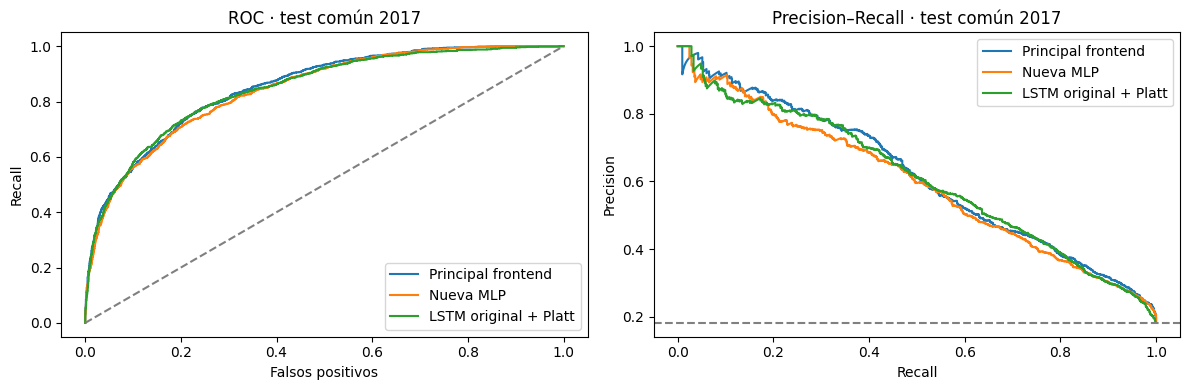

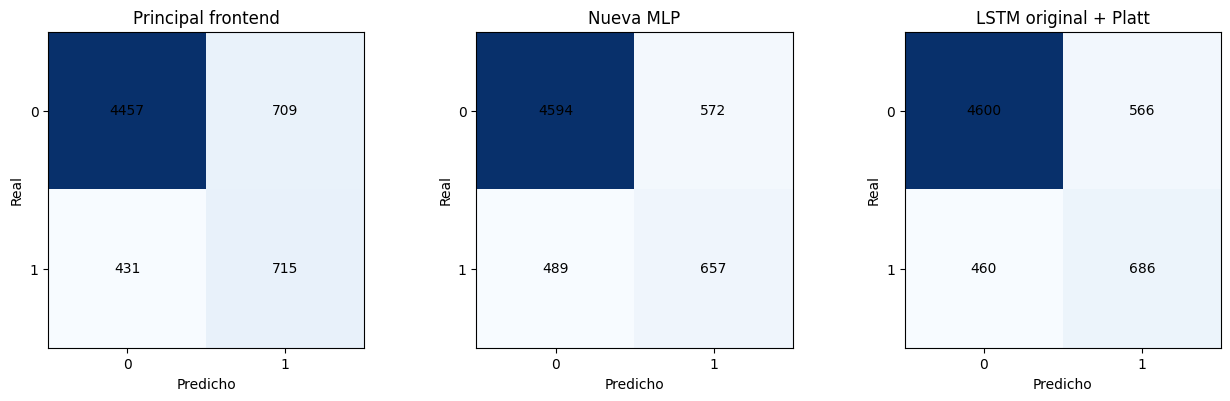

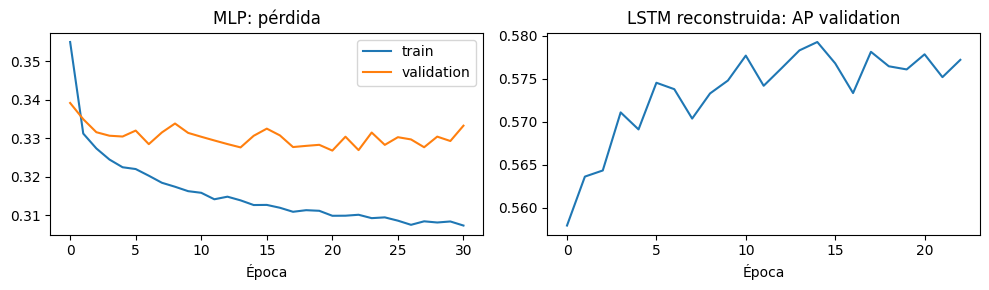

In [19]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name,col,thr,origin in main_specs:
    fpr,tpr,_=roc_curve(y_common,common[col]);axes[0].plot(fpr,tpr,label=name)
    precision,recall,_=precision_recall_curve(y_common,common[col]);axes[1].plot(recall,precision,label=name)
axes[0].plot([0,1],[0,1],'--',color='grey');axes[0].set(xlabel='Falsos positivos',ylabel='Recall',title='ROC · test común 2017')
axes[1].axhline(y_common.mean(),ls='--',color='grey');axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–Recall · test común 2017')
for ax in axes:ax.legend()
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,(name,col,thr,origin) in zip(axes,main_specs):
    cm=confusion_matrix(y_common,common[col]>=thr,labels=[0,1]);ax.imshow(cm,cmap='Blues')
    for (r,c),value in np.ndenumerate(cm):ax.text(c,r,str(value),ha='center',va='center')
    ax.set(xticks=[0,1],yticks=[0,1],xlabel='Predicho',ylabel='Real',title=name)
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(10,3))
axes[0].plot(h_mlp.history['loss'],label='train');axes[0].plot(h_mlp.history['val_loss'],label='validation')
axes[0].set(title='MLP: pérdida',xlabel='Época');axes[0].legend()
axes[1].plot(h_lstm.history['val_ap_exact']);axes[1].set(title='LSTM reconstruida: AP validation',xlabel='Época')
plt.tight_layout();plt.show()

## 13 · Guardado y trazabilidad

Se exportan las tablas, todas las probabilidades comunes y los modelos/preprocesadores
de los reentrenamientos. No se modifica el frontend ni sus archivos originales.
La configuración registra semillas, umbrales, procedencias y versiones.

In [20]:
OUTDIR=RAIZ/'artifacts/comparacion_frontend_mlp_lstm'
OUTDIR.mkdir(parents=True,exist_ok=True)
tables={'comparacion_frontend_original':comparison_original,'comparacion_reentrenamientos':comparison_retrained,
    'diferencias_vs_frontend':deltas,'auditoria_metricas_originales':historical_verified,
    'cobertura_muestra_comun':coverage,'particiones':partition_table,'predicciones_comunes_2017':common}
for name,table in tables.items():table.to_csv(OUTDIR/(name+'.csv'),index=False)
mlp.save(OUTDIR/'mlp_presencia.keras');lstm.save(OUTDIR/'lstm_presencia_reconstruida.keras')
joblib.dump({'rf':rf_final,'rf_platt':rf_platt,'rf_rr':rr_final,'rf_season_selected':rf_use_season,
    'mlp_prep':mlp_prep,'lstm_prep':seq_prep,'lstm_platt':lstm_platt,
    'mlp_features':MLP_FEATURES,'lstm_features':seq_features,'window':WINDOW,
    'thresholds':{'frontend_original':THR_FRONT_ORIGINAL,'lstm_original':THR_LSTM_ORIGINAL,
        'rf_retrained':THR_RF_RETRAINED,'mlp':THR_MLP,'lstm_retrained':THR_LSTM_RETRAINED}},
    OUTDIR/'modelos_y_preprocesamiento.joblib')
config={'seed':SEED,'quick_run':QUICK_RUN,'reference_source':str(REFERENCE_SOURCE),
    'raw_data':DATA_SOURCE,'raw_audit':audit_input,
    'reference_sha256':{name:hashlib.sha256(reference_bytes(name)).hexdigest() for name in REFERENCE_FILES},
    'test_rows_common':len(common),'test_cells_common':int(common['cell'].nunique()),
    'mlp_training':'2009-2015; early stopping y umbral en 2016',
    'rf_training':'OOF 2013-2016; refit 2008-2016; datos AADF contemporáneos del Reto 5',
    'lstm_training':'reconstrucción; ventanas 12; train 2010-2015, validación/calibración 2016',
    'lstm_original_code_available':False,'rf_params':RF_PARAMS,
    'mlp_epochs':len(h_mlp.history['loss']),'lstm_epochs':len(h_lstm.history['loss']),
    'versions':{'numpy':np.__version__,'pandas':pd.__version__,'tensorflow':tf.__version__,
                'scikit-learn':__import__('sklearn').__version__}}
(OUTDIR/'configuracion.json').write_text(json.dumps(config,indent=2,default=lambda x:int(x) if isinstance(x,np.integer) else str(x)),encoding='utf-8')
print('Archivos exportados en:',OUTDIR.resolve())

Archivos exportados en: C:\Users\Gabriel\Documents\GitHub\IA\artifacts\comparacion_frontend_mlp_lstm


## Lectura del resultado

- La tabla principal contesta si la nueva MLP o la LSTM original mejoran al frontend
  **en las mismas filas**. Los resultados son descriptivos de test, sin retocar modelos.
- La segunda tabla permite evaluar la réplica de RF y la reconstrucción LSTM.
- La F1 depende de los umbrales elegidos en 2016; AP y ROC-AUC no.
- La muestra común iguala las observaciones de evaluación, pero se conservan los
  distintos protocolos de entrenamiento y la información disponible para cada modelo.
- Repetir la arquitectura MLP de forma aislada puede cambiar el resultado por el
  estado aleatorio y por librerías/hardware. No se fijan las métricas esperadas en código.

Comprobación del archivo: estructura y ejecución de integración con datos de prueba
separados. La ejecución con AADF/DVC reales se realiza dentro de tu proyecto.
Fuentes: cuaderno del capítulo 8 ejecutado, Reto 5 adjunto y archivos por fila del ZIP V11.